# Analisis data pembelajaran

## Import

In [10]:
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="darkgrid")

def manual_cluster(x:float,y:float, avg_x:float, avg_y:float)->str:
    if x < avg_x and y < avg_y:
        return 'Gulper'
    elif x >= avg_x and y < avg_y:
        return 'Big Eater'
    elif x < avg_x and y >= avg_y:
        return 'Picky Eater'
    else:
        return 'Nibbler'
    
manual_label = ['Big Eater', 'Gulper', 'Nibbler', 'Picky Eater']
    

## Load data dan klasifikasi

In [11]:
df = pl.read_csv('data.csv', separator=';',decimal_comma=True)\
    .with_columns(pl.col('LearningTime').log(base=60).alias('Log60LearningTime'))\
    .with_columns(pl.col('SpacingTime').log(base=60).alias('Log60SpacingTime'))

avg_LearningTimeSec = np.mean(df.select(pl.col('Log60LearningTime')).to_numpy())
avg_SpacesTimeSec = np.mean(df.select(pl.col('Log60SpacingTime')).to_numpy())

df = df.with_columns(
    pl.struct(['Log60LearningTime', 'Log60SpacingTime'])
    .map_elements(
        lambda i: manual_cluster(
            i['Log60LearningTime'], i['Log60SpacingTime'], 
            avg_LearningTimeSec, avg_SpacesTimeSec
        ), return_dtype=str
    )
    .alias('ManualLabel')
)

df_pandas = df.to_pandas()

## Deskripsi Data

In [12]:
df_pandas.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,75712.0,37856.500000,21856.316128,1.000000,18928.750000,37856.500000,56784.250000,7.571200e+04
LearningTime,75712.0,73836.734784,229409.397407,35.000000,529.000000,2897.500000,21045.250000,8.726217e+06
SpacingTime,75712.0,37372.769350,176230.273115,8.000000,145.000000,494.000000,3689.000000,8.285201e+06
HighestScore,75712.0,78.469560,12.371639,0.000000,66.670000,80.000000,86.670000,1.000000e+02
NumberTestTaken,75712.0,3.410978,2.726944,0.000000,1.000000,3.000000,5.000000,2.900000e+01
Log60LearningTime,75712.0,2.045273,0.610733,0.868356,1.531622,1.946979,2.431263,3.903395e+00
Log60SpacingTime,75712.0,1.684227,0.614614,0.507881,1.215514,1.514903,2.005965,3.890728e+00


## Ilustrasi

### Scatterplot

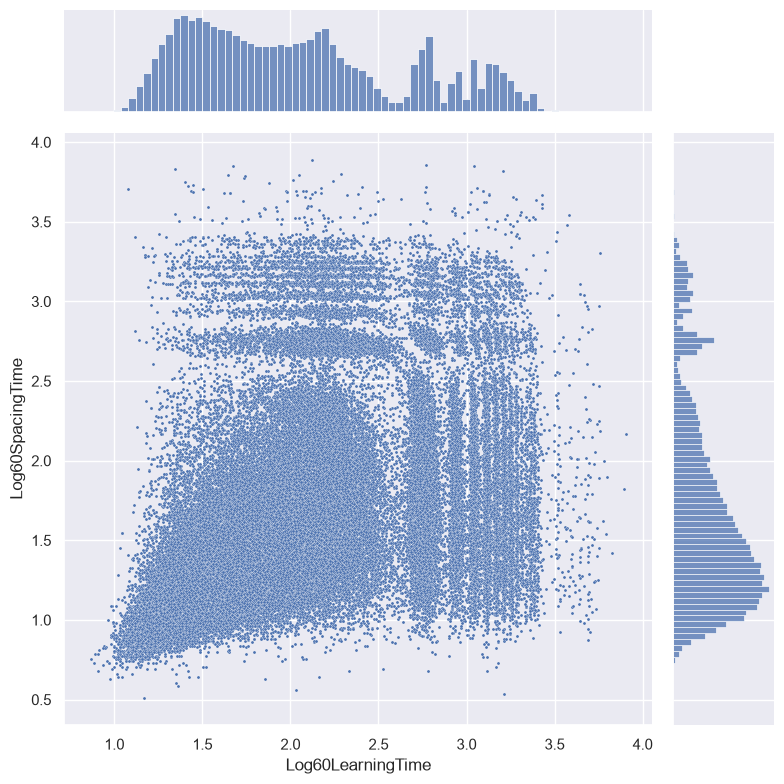

In [13]:
sns.jointplot(
    df_pandas,
    x='Log60LearningTime',
    y='Log60SpacingTime',
    height=8,
    s=5,
)

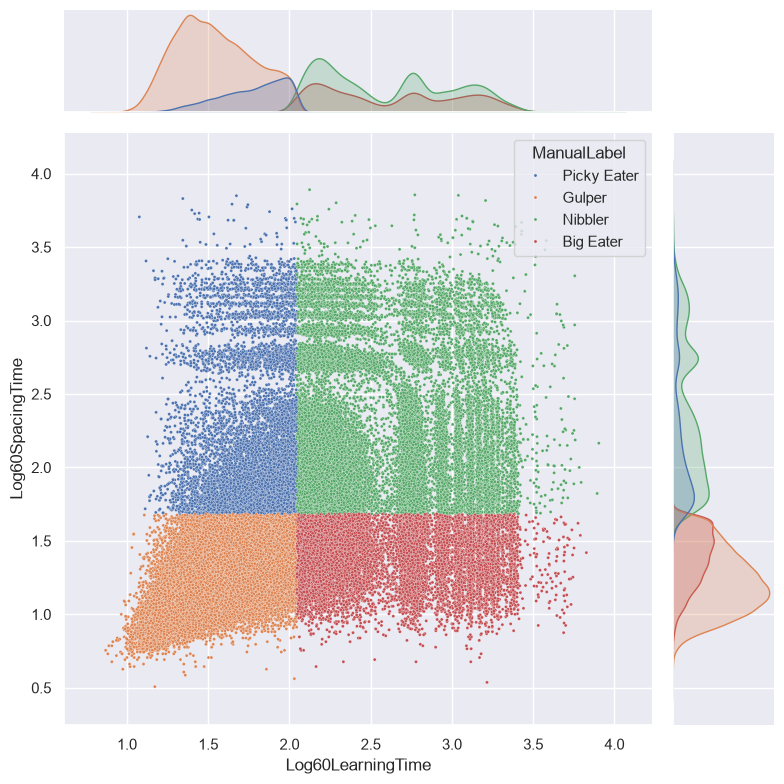

In [14]:
sns.jointplot(
    df_pandas,
    x='Log60LearningTime',
    y='Log60SpacingTime',
    height=8,
    hue='ManualLabel',
    s=5,
)

## Analisis dan Visualisasi

### Berdasarkan Gender

#### Contingency Table

In [15]:
tbl_gender = pd.crosstab(
    df_pandas['Gender'],
    df_pandas['ManualLabel'],
)

## add total row and column
tbl_gender.loc['Total'] = tbl_gender.sum()
tbl_gender['Total'] = tbl_gender.sum(axis=1)

tbl_gender


ManualLabel,Big Eater,Gulper,Nibbler,Picky Eater,Total
Gender,,,,,
L,8420,24176,13279,5543,51418
P,4224,9105,7859,3106,24294
Total,12644,33281,21138,8649,75712


#### Tabel Persentase Gender vs Kluster (%)

In [16]:
tbl_gender_pct = pd.crosstab(
    df_pandas['Gender'], 
    df_pandas['ManualLabel'], 
    normalize='index'
).mul(100).round(2)

tbl_gender_pct

ManualLabel,Big Eater,Gulper,Nibbler,Picky Eater
Gender,,,,
L,16.38,47.02,25.83,10.78
P,17.39,37.48,32.35,12.79


#### Visualisasi

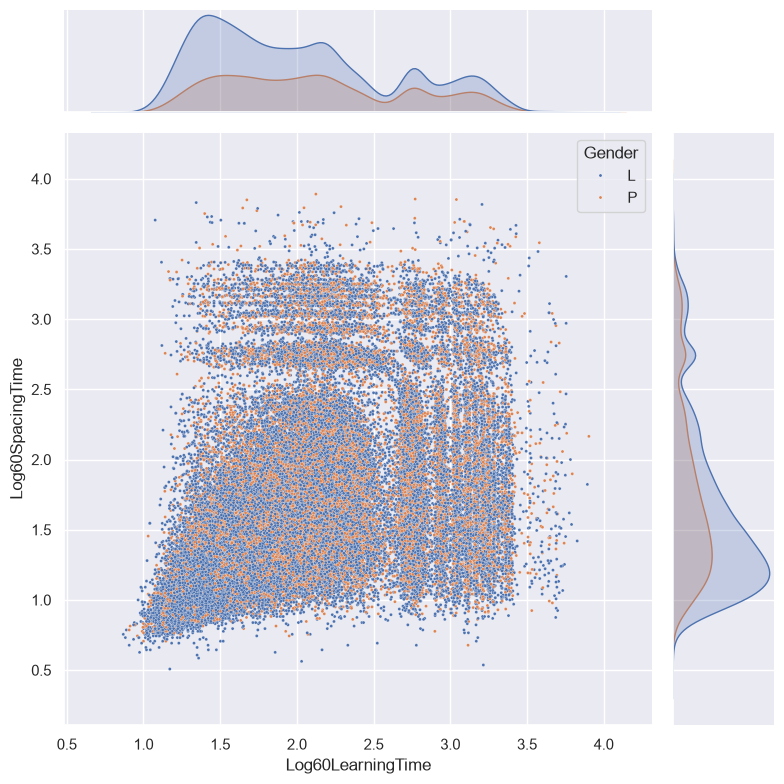

In [17]:
sns.jointplot(
    df_pandas,
    x='Log60LearningTime',
    y='Log60SpacingTime',
    hue='Gender',
    height=8,
    s=5,
)

#### Uji statistik

In [18]:
# uji chi-square test

chi2, p, dof, expected = chi2_contingency(tbl_gender.iloc[:-1, :-1]) # exclude the total row and column

print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4f}")

Chi-square statistic: 661.283
Degrees of freedom: 3
P-value: 0.0000


Simpulan: Terdapat perbedaan proporsi antar kategori

### Berdasarkan Generasi

#### Contingency Table

In [19]:
tbl_generation = pd.crosstab(
    df_pandas['Generation'],
    df_pandas['ManualLabel'],
)

## add total row and column
tbl_generation.loc['Total'] = tbl_generation.sum()
tbl_generation['Total'] = tbl_generation.sum(axis=1)

tbl_generation


ManualLabel,Big Eater,Gulper,Nibbler,Picky Eater,Total
Generation,,,,,
B,11,25,13,7,56
X,4522,6904,8198,1747,21371
Y,6324,18965,10089,4806,40184
Z,1787,7387,2838,2089,14101
Total,12644,33281,21138,8649,75712


#### Tabel Persentase Generasi vs Kluster (%)

In [20]:
tbl_generation_pct = pd.crosstab(
    df_pandas['Generation'],
    df_pandas['ManualLabel'],
    normalize='index'
).mul(100).round(2)

tbl_generation_pct

ManualLabel,Big Eater,Gulper,Nibbler,Picky Eater
Generation,,,,
B,19.64,44.64,23.21,12.50
X,21.16,32.31,38.36,8.17
Y,15.74,47.20,25.11,11.96
Z,12.67,52.39,20.13,14.81


#### Visualisasi

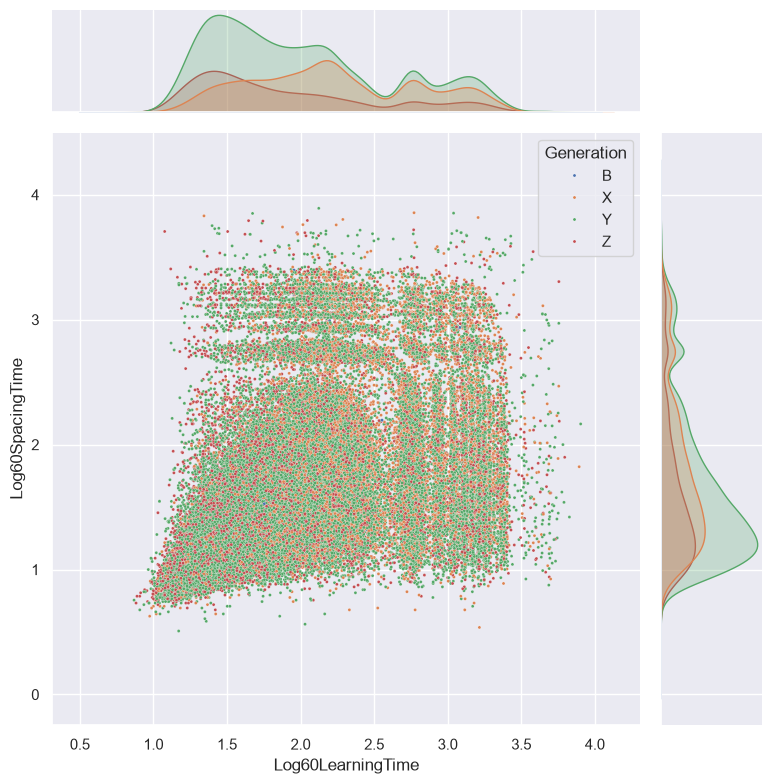

In [21]:
sns.jointplot(
    df_pandas,
    x='Log60LearningTime',
    y='Log60SpacingTime',
    hue='Generation',
    height=8,
    hue_order='BXYZ',
    s=5,
)

#### Uji statistik

In [22]:
# uji chi-square test

chi2, p, dof, expected = chi2_contingency(tbl_generation.iloc[:-1, :-1]) # exclude the total row and column

print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4f}")

Chi-square statistic: 3002.933
Degrees of freedom: 9
P-value: 0.0000


## Regresi (Negatif Binomial)

In [23]:
df.select([
    pl.col('NumberTestTaken').mean().alias('Mean'),
    pl.col('NumberTestTaken').var().alias('Variance'),
    pl.col('NumberTestTaken').std().alias('Standard Deviation'),
    pl.col('NumberTestTaken').min().alias('Minimum'),
    pl.col('NumberTestTaken').max().alias('Maximum'),
])

Mean,Variance,Standard Deviation,Minimum,Maximum
f64,f64,f64,i64,i64
3.410978,7.436225,2.726944,0,29


In [24]:
import statsmodels.discrete.discrete_model as smd

model = smd.NegativeBinomial.from_formula(
    formula = 'NumberTestTaken ~ C(ManualLabel) + C(Gender) + C(Generation)',
    data = df_pandas
).fit()

Optimization terminated successfully.
         Current function value: 2.189353
         Iterations: 15
         Function evaluations: 17
         Gradient evaluations: 17


In [25]:
print(model.summary())

                     NegativeBinomial Regression Results                      
Dep. Variable:        NumberTestTaken   No. Observations:                75712
Model:               NegativeBinomial   Df Residuals:                    75704
Method:                           MLE   Df Model:                            7
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                0.006755
Time:                        09:07:18   Log-Likelihood:            -1.6576e+05
converged:                       True   LL-Null:                   -1.6689e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                         1.0081      0.106      9.545      0.000       0.801       1.215
C(ManualLabel)[T.Gulper]         -0.0039      0.008     -0.507      0.612 

**Simpulan**
Hasil GLM dengan negative binomial menunjukkan bahwa Klasifikasi tipe belajar berdasarkan waktu belajar dan waktu jeda tidak berpengaruh terhadap jumlah tes yang diambil (semua tipe memiliki probabilitas yang cenderung sama untuk mengulang tes).

**Temuan menarik**
- Perempuan cenderung memiliki lebih sedikit jumlah tes yang dilakukan atau dengan kata lain sedikit mengulang tes, perlu ditelusuri apakah karena nilainya relatif lebih bagus atau tidak memiliki insentif untuk mengulang tes
- Mengapa Gen Y dan Gen Z cenderung mengulang tes?

-----